# 03 — Análise Exploratória: dividendos Trading 212

Objetivo: explorar o dataset padronizado para perceber padrões, distribuições e relações entre variáveis antes de escolher a abordagem de modelação.

**Entrada**
- Dataset padronizado gerado no notebook `02_standardization`

**Colunas disponíveis após a padronização**
- Identificação do ativo: `ticker`, `name`, `isin`, `currency`, `sector`
- Data do pagamento: `paidOn` (UTC), `payDate` (data sem hora)
- Valores: `quantity`, `grossAmountPerShare`, `totalGrossAmountOriginalCurrency`, `grossAmountInEuro`, `amountInEuro` (líquido)
- Câmbio: `Date`, `fxEurUsd`

## 1. Imports

In [66]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

## 2. Carregamento dos dados

In [48]:
output_path = Path.cwd().parent / 'output'

df = pd.read_csv(output_path / 'dividends_standardized.csv', parse_dates=['paidOn', 'payDate'])

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 14 columns):
 #   Column                            Non-Null Count  Dtype              
---  ------                            --------------  -----              
 0   ticker                            145 non-null    object             
 1   name                              145 non-null    object             
 2   isin                              145 non-null    object             
 3   currency                          145 non-null    object             
 4   amountInEuro                      145 non-null    float64            
 5   paidOn                            145 non-null    datetime64[ns, UTC]
 6   grossAmountPerShare               145 non-null    float64            
 7   quantity                          145 non-null    float64            
 8   sector                            145 non-null    object             
 9   totalGrossAmountOriginalCurrency  145 non-null    float64        

In [50]:
# Rename  Date in capital to date in lower casa
df.rename(columns={'Date': 'date'}, inplace=True)

In [51]:
df.columns

Index(['ticker', 'name', 'isin', 'currency', 'amountInEuro', 'paidOn',
       'grossAmountPerShare', 'quantity', 'sector',
       'totalGrossAmountOriginalCurrency', 'payDate', 'date', 'fxEurUsd',
       'grossAmountInEuro'],
      dtype='object')

In [52]:
# Concentração dos ativos na carteira
total_received = df['amountInEuro'].sum()
df.groupby('sector')['amountInEuro'].agg(
    mean='mean',
    min='min',
    max='max',
    count='count',
    pct = lambda s: ((s.sum()) / total_received) * 100
).sort_values('pct',ascending=False)

,mean,min,max,count,pct
sector,,,,,
Real Estate,0.625200,0.04,1.12,75,49.968031
Financial Services,0.726500,0.22,1.12,40,30.967604
Healthcare,1.217500,0.01,1.57,8,10.379369
ETF,0.373846,0.01,0.63,13,5.179028
Basic Materials,0.410000,0.15,0.75,8,3.495311
Consumer Defensive,0.010000,0.01,0.01,1,0.010656


In [53]:
top_5_best_dividends = df.groupby('name')['amountInEuro'].sum().sort_values(ascending=False).head(5)

In [54]:
top_5_best_dividends

name
Main Street Capital    27.26
EPR Properties         25.09
Realty Income          15.75
Pfizer                  9.73
AGNC Investment         3.99
Name: amountInEuro, dtype: float64

In [55]:
# Mês do ano que mais recebi dividendos
# 1º Criar a coluna de mê
df['month'] = df['payDate'].dt.month_name()

In [56]:
df.groupby(df['payDate'].dt.month_name())['amountInEuro'].sum().sort_values(ascending=False)

payDate
September    13.54
March        11.45
June         10.98
October       9.52
December      8.94
August        7.02
July          6.33
January       6.10
February      5.59
May           5.15
April         5.06
November      4.16
Name: amountInEuro, dtype: float64

**Atenção:** a soma por mês junta anos diferentes. Os dados vão de julho de 2024 a outubro de 2026, por isso julho a outubro aparecem 3 vezes e os restantes meses só 2. A carteira também cresceu ao longo do tempo, o que dá mais peso aos meses recentes.

Para comparar meses de forma justa, é preciso separar por ano:

In [60]:
# Total recebido por ano (linhas) e mês (colunas)
monthly = df.pivot_table(
    index=df['payDate'].dt.year,
    columns=df['payDate'].dt.month,
    values='amountInEuro',
    aggfunc='sum',
).fillna(0)
monthly

payDate,1,2,3,4,5,6,7,8,9,10,11,12
payDate,,,,,,,,,,,,
2024,0.00,0.00,0.00,0.00,0.00,0.00,0.04,0.26,0.67,1.20,1.67,4.06
2025,3.11,3.07,5.59,2.43,2.47,4.68,2.38,2.38,5.30,2.46,2.49,4.88
2026,2.99,2.52,5.86,2.63,2.68,6.30,3.91,4.38,7.57,5.86,0.00,0.00


### Gráfico: recebido por mês, por ano
Os picos em março, junho, setembro e dezembro vêm dos ativos que pagam trimestralmente.

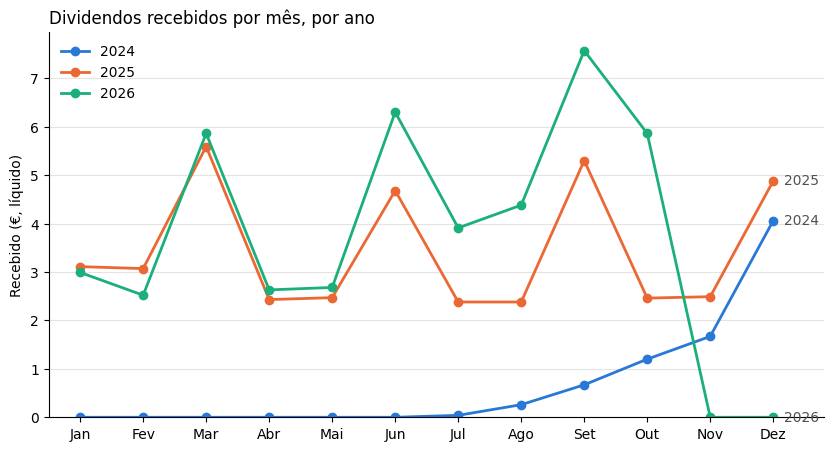

In [ ]:

colors = {2024: '#2a78d6', 2025: '#eb6834', 2026: '#1baf7a'}
month_labels = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

fig, ax = plt.subplots(figsize=(10, 5))

for year, row in monthly.iterrows():
    ax.plot(row.index, row.values, marker='o', linewidth=2, markersize=6,
            color=colors[year], label=str(year))
  
    last = row.dropna()
    ax.annotate(str(year), (last.index[-1], last.iloc[-1]), xytext=(8, 0),
                textcoords='offset points', va='center', color='#52514e')

ax.set_xticks(range(1, 13), month_labels)
ax.set_xlim(0.5, 12.8)
ax.set_ylim(bottom=0)
ax.set_ylabel('Recebido (€, líquido)')
ax.set_title('Dividendos recebidos por mês, por ano', loc='left')
ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc='upper left')

plt.show()

In [64]:
df.groupby([df['payDate'].dt.year.rename('year'),df['payDate'].dt.month.rename('month')])['amountInEuro'].sum().unstack().fillna(0)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2024,0.00,0.00,0.00,0.00,0.00,0.00,0.04,0.26,0.67,1.20,1.67,4.06
2025,3.11,3.07,5.59,2.43,2.47,4.68,2.38,2.38,5.30,2.46,2.49,4.88
2026,2.99,2.52,5.86,2.63,2.68,6.30,3.91,4.38,7.57,5.86,0.00,0.00
